In [1]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True, return_X_y=True)
df, target = data[0], data[1] 

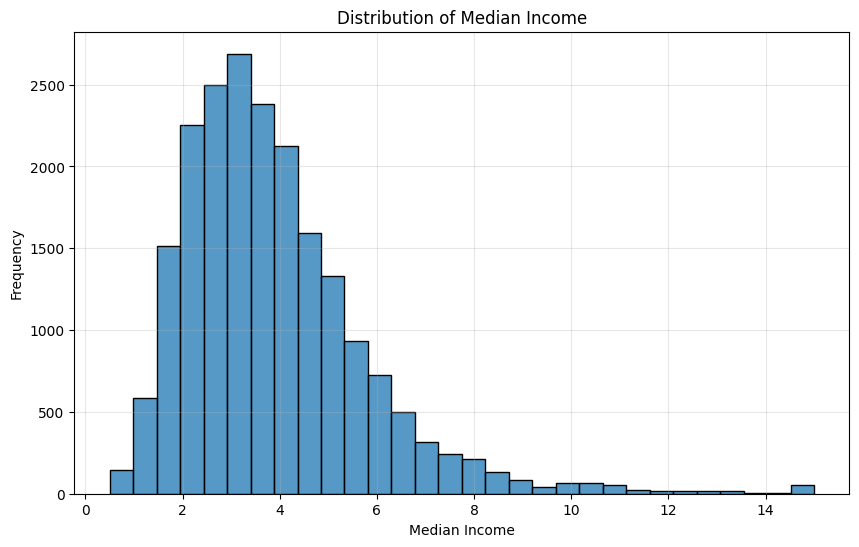

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['MedInc'], bins=30)
plt.title('Distribution of Median Income')
plt.xlabel('Median Income')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

Оптимальный параметр a:     4.7491
Оптимальный параметр scale: 0.8150


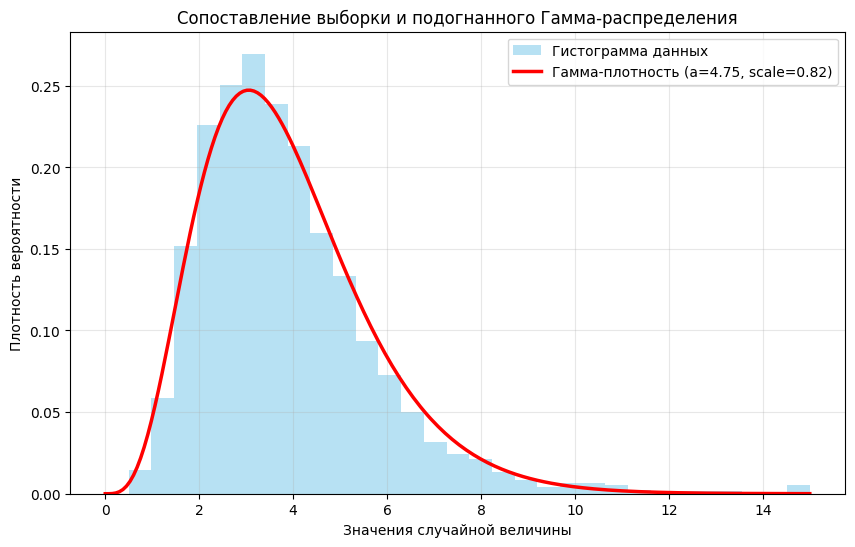

In [8]:
from scipy.stats import gamma
from scipy.optimize import minimize
import numpy as np

# 1. Функция вычисления минус логарифма правдоподобия
def negative_log_likelihood(params, data):
    a, scale = params
    # loc зафиксирован равным 0 по условию задачи
    # stats.gamma.logpdf возвращает логарифм плотности вероятности для каждой точки
    log_pdfs = gamma.logpdf(data, a=a, loc=0, scale=scale)
    
    # Возвращаем СУММУ с отрицательным знаком для минимизации
    return -np.sum(log_pdfs)

# --- Примечание: Для проверки замените `your_data_series` на ваш столбец с данными ---
# Например: data_sample = df['AveRooms'] 

data_sample = df['MedInc']

# 2. Оптимизация параметров с помощью minimize
initial_guess = [1, 2]  # Начальные приближения по условию: a=1, scale=2

result = minimize(
    fun=negative_log_likelihood,
    x0=initial_guess,
    args=(data_sample,),  # передаем наши данные внутрь функции правдоподобия
    method='L-BFGS-B',
    # bounds=[(1e-5, None), (1e-5, None)] # параметры a и scale должны быть строго положительными чисел
)

# Извлекаем найденные оптимальные параметры
a_opt, scale_opt = result.x
print(f"Оптимальный параметр a:     {a_opt:.4f}")
print(f"Оптимальный параметр scale: {scale_opt:.4f}")


# 3. Визуализация для проверки (построение графиков)
plt.figure(figsize=(10, 6))

# Строим гистограмму выборки (density=True обязателен, чтобы масштабы плотности совпали)
plt.hist(data_sample, bins=30, density=True, alpha=0.6, color='skyblue', label='Гистограмма данных')

# Создаем равномерную сетку точек для построения теоретической плотности
x_grid = np.linspace(0, np.max(data_sample), 200)

# Считаем теоретическую плотность распределения (pdf) с найденными параметрами
pdf_values = gamma.pdf(x_grid, a=a_opt, loc=0, scale=scale_opt)

# Отображаем линию плотности распределения
plt.plot(x_grid, pdf_values, color='red', linewidth=2.5, label=f'Гамма-плотность (a={a_opt:.2f}, scale={scale_opt:.2f})')

plt.title('Сопоставление выборки и подогнанного Гамма-распределения')
plt.xlabel('Значения случайной величины')
plt.ylabel('Плотность вероятности')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
